In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/khushikyad001/public-transport-delays-with-weather-and-events/public_transport_delays.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
df = pd.read_csv("PASTE_PATH_HERE")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'PASTE_PATH_HERE'

In [3]:
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/khushikyad001/public-transport-delays-with-weather-and-events/public_transport_delays.csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
df = pd.read_csv("/kaggle/input/datasets/khushikyad001/public-transport-delays-with-weather-and-events/public_transport_delays.csv")
df.head()

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1


In [6]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   trip_id                     2000 non-null   object 
 1   date                        2000 non-null   object 
 2   time                        2000 non-null   object 
 3   transport_type              2000 non-null   object 
 4   route_id                    2000 non-null   object 
 5   origin_station              2000 non-null   object 
 6   destination_station         2000 non-null   object 
 7   scheduled_departure         2000 non-null   object 
 8   scheduled_arrival           2000 non-null   object 
 9   actual_departure_delay_min  2000 non-null   int64  
 10  actual_arrival_delay_min    2000 non-null   int64  
 11  weather_condition           2000 non-null   object 
 12  temperature_C               2000 non-null   float64
 13  humidity_percent            2000 

In [7]:
print(df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print(df.shape)

trip_id                          0
date                             0
time                             0
transport_type                   0
route_id                         0
origin_station                   0
destination_station              0
scheduled_departure              0
scheduled_arrival                0
actual_departure_delay_min       0
actual_arrival_delay_min         0
weather_condition                0
temperature_C                    0
humidity_percent                 0
wind_speed_kmh                   0
precipitation_mm                 0
event_type                    1173
event_attendance_est             0
traffic_congestion_index         0
holiday                          0
peak_hour                        0
weekday                          0
season                           0
delayed                          0
dtype: int64
Duplicates: 0
(2000, 24)


In [8]:
print(df["date"].min(), "->", df["date"].max())
print(df["actual_arrival_delay_min"].describe())
print(df["delayed"].value_counts())

2023-01-01 -> 2023-01-22
count    2000.000000
mean       13.318000
std         9.289727
min        -3.000000
25%         5.000000
50%        13.000000
75%        21.000000
max        29.000000
Name: actual_arrival_delay_min, dtype: float64
delayed
1    1499
0     501
Name: count, dtype: int64


In [9]:
df["event_type"] = df["event_type"].fillna("No event")
df["date"] = pd.to_datetime(df["date"])

df["hour"] = pd.to_datetime(df["time"], format="%H:%M:%S").dt.hour

dep = pd.to_datetime(df["scheduled_departure"], format="%H:%M:%S")
arr = pd.to_datetime(df["scheduled_arrival"], format="%H:%M:%S")
df["scheduled_duration_min"] = ((arr - dep).dt.total_seconds() / 60) % (24 * 60)

df["has_event"] = (df["event_type"] != "No event").astype(int)
df["is_weekend"] = (df["weekday"] >= 5).astype(int)
df["is_rainy"] = (df["precipitation_mm"] > 0).astype(int)

df = df.sort_values(["date", "time"]).reset_index(drop=True)
df[["hour", "scheduled_duration_min", "has_event", "is_weekend", "is_rainy"]].describe()

,hour,scheduled_duration_min,has_event,is_weekend,is_rainy
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,11.572000,37.003500,0.413500,0.280000,0.997000
std,6.903669,11.341243,0.492584,0.449111,0.054704
min,0.000000,16.000000,0.000000,0.000000,0.000000
25%,6.000000,27.000000,0.000000,0.000000,1.000000
50%,12.000000,37.000000,0.000000,0.000000,1.000000
75%,18.000000,47.000000,1.000000,1.000000,1.000000
max,23.000000,59.000000,1.000000,1.000000,1.000000


In [10]:
df["month"] = df["date"].dt.month
print(pd.crosstab(df["month"], df["season"]))
print((df["date"].dt.weekday == df["weekday"]).mean())

season  Autumn  Spring  Summer  Winter
month                                 
1          480     502     524     494
1.0


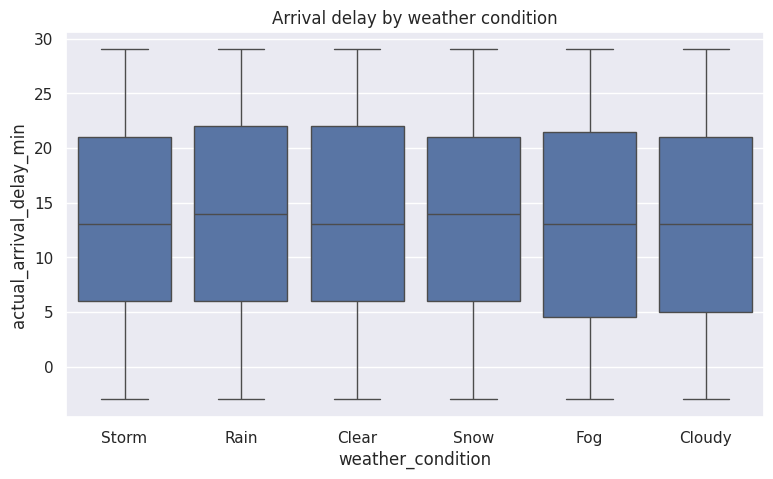

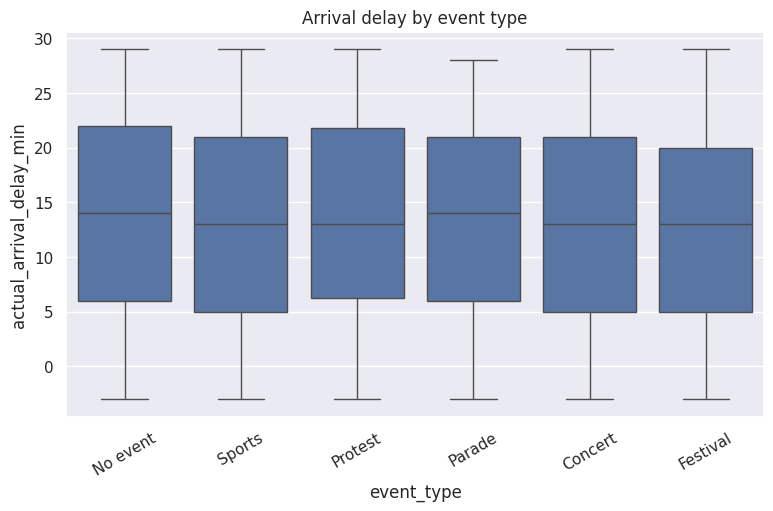

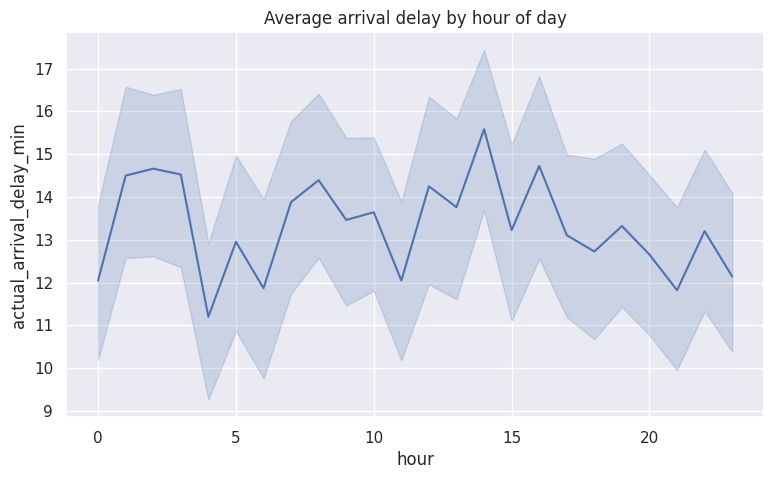

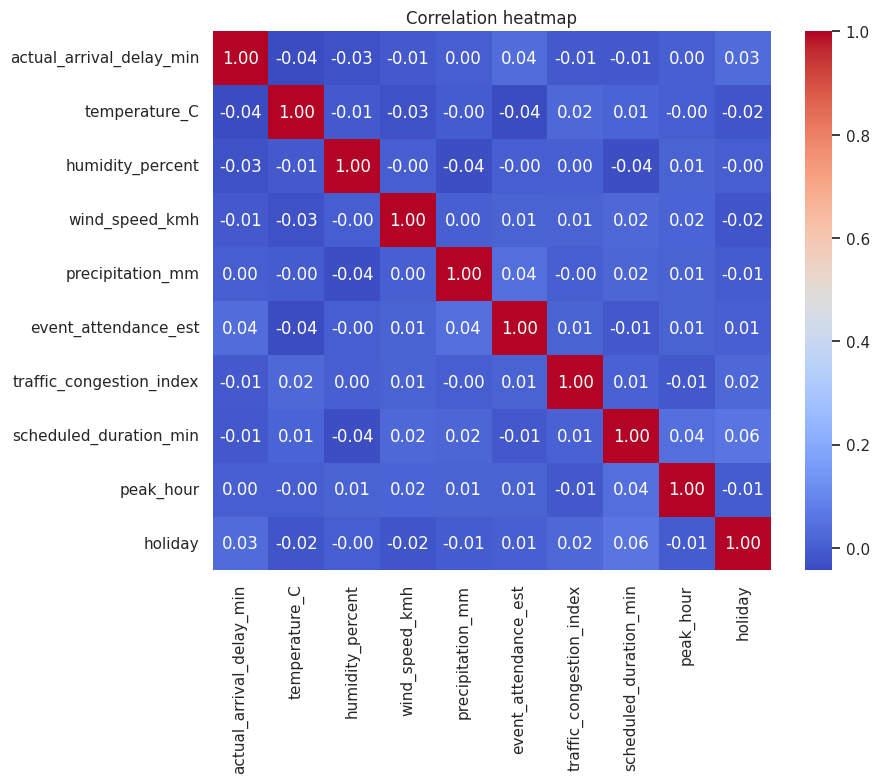

In [11]:
import os
os.makedirs("/kaggle/working/images", exist_ok=True)
target = "actual_arrival_delay_min"

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="weather_condition", y=target, ax=ax)
ax.set_title("Arrival delay by weather condition")
plt.savefig("/kaggle/working/images/delay_by_weather.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=df, x="event_type", y=target, ax=ax)
ax.set_title("Arrival delay by event type")
plt.xticks(rotation=30)
plt.savefig("/kaggle/working/images/delay_by_event.png", bbox_inches="tight", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
sns.lineplot(data=df, x="hour", y=target, ax=ax)
ax.set_title("Average arrival delay by hour of day")
plt.savefig("/kaggle/working/images/delay_by_hour.png", bbox_inches="tight", dpi=150)
plt.show()

num_cols = ["actual_arrival_delay_min", "temperature_C", "humidity_percent", "wind_speed_kmh",
            "precipitation_mm", "event_attendance_est", "traffic_congestion_index",
            "scheduled_duration_min", "peak_hour", "holiday"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation heatmap")
plt.savefig("/kaggle/working/images/correlation.png", bbox_inches="tight", dpi=150)
plt.show()

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

cat_features = ["transport_type", "weather_condition", "event_type", "season"]
num_features = ["temperature_C", "humidity_percent", "wind_speed_kmh", "precipitation_mm",
                "event_attendance_est", "traffic_congestion_index", "holiday", "peak_hour",
                "weekday", "hour", "scheduled_duration_min", "has_event", "is_weekend", "is_rainy"]

X = df[cat_features + num_features]
y = df[target]

# time-based split: first 80% of rows for training, last 20% for testing
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
                        remainder="passthrough")

models = {
    "Baseline (mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42),
}

results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("pre", pre), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"Model": name,
                    "MAE": mean_absolute_error(y_test, pred),
                    "RMSE": np.sqrt(mean_squared_error(y_test, pred))})
    fitted[name] = pipe

results_df = pd.DataFrame(results).round(2)
results_df

,Model,MAE,RMSE
0,Baseline (mean),8.15,9.46
1,Linear Regression,8.24,9.59
2,Random Forest,8.22,9.56
3,XGBoost,8.36,9.84


In [13]:
from scipy import stats

for col in ["weather_condition", "event_type", "transport_type", "season"]:
    groups = [g[target].values for _, g in df.groupby(col)]
    stat, p = stats.kruskal(*groups)
    print(f"{col:20s} p-value = {p:.3f}")
    print(df.groupby(col)[target].mean().round(2).to_string(), "\n")

weather_condition    p-value = 0.904
weather_condition
Clear     13.50
Cloudy    13.07
Fog       12.88
Rain      13.62
Snow      13.53
Storm     13.29 

event_type           p-value = 0.704
event_type
Concert     12.83
Festival    12.77
No event    13.53
Parade      13.62
Protest     13.90
Sports      12.82 

transport_type       p-value = 0.701
transport_type
Bus      13.54
Metro    13.21
Train    13.55
Tram     12.95 

season               p-value = 0.256
season
Autumn    13.89
Spring    13.40
Summer    12.72
Winter    13.31 



In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

clf = Pipeline([("pre", pre), ("model", RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1))])
clf.fit(X_train, df["delayed"].iloc[:split])
proba = clf.predict_proba(X_test)[:, 1]
print("ROC-AUC:", round(roc_auc_score(df["delayed"].iloc[split:], proba), 3))
print(df.groupby("delayed")[["actual_departure_delay_min", target]].mean())

ROC-AUC: 0.473
         actual_departure_delay_min  actual_arrival_delay_min
delayed                                                      
0                          8.798403                  1.049900
1                          8.651101                 17.418279


# Can weather and events predict public transport delays?

**TL;DR:** No. On this dataset, none of the models beat a naive baseline,
and statistical tests found no relationship between weather/events and delays.

## Question
Do weather conditions and city events help predict arrival delay (minutes)?

## Method
- Dataset: Kaggle "Public Transport Delays with Weather and Events" (2,000 trips)
- Features: weather, temperature, humidity, wind, precipitation, event type/attendance,
  congestion index, holiday, peak hour, weekday, hour, scheduled duration
- Excluded `actual_departure_delay_min` and `delayed` to avoid data leakage
- Time-ordered 80/20 train/test split
- Models: mean baseline, Linear Regression, Random Forest, XGBoost

## Results
| Model | MAE (min) | RMSE (min) |
|---|---|---|
| Baseline (mean) | 8.15 | 9.46 |
| Linear Regression | 8.24 | 9.59 |
| Random Forest | 8.22 | 9.56 |
| XGBoost | 8.36 | 9.84 |

- No model beat the baseline
- Kruskal-Wallis tests: weather (p=0.90), event type (p=0.70),
  transport type (p=0.70), season (p=0.26), all non-significant
- Classifying the `delayed` flag: ROC-AUC 0.47 (random guessing)
- All feature correlations with delay were within ±0.04

## Conclusion
The dataset appears to be synthetic: delays show no dependence on weather,
events, or even departure delay. Reporting this honestly matters more than
forcing a model to look good.

## What I'd do next
Repeat the analysis on real data, such as a city's open GTFS-realtime
feed joined with historical weather data.

## Run it
1. Download the dataset from Kaggle into `data/`
2. `pip install -r requirements.txt`
3. Run `notebooks/01_eda_and_model.ipynb`

In [16]:
git add .
git commit -m "Add EDA, models, and null-result write-up"
git push

SyntaxError: invalid syntax (2679668789.py, line 1)